# 03 · Gradient boosting and SHAP

Model-free check on the functional form. Target: NIMQR. Model: scikit-learn `HistGradientBoostingRegressor` (600 iterations, learning rate 0.03, depth 4). Time-based split: the last 8 quarters are the test set (train 601,148 rows, test 38,723 rows). Test RMSE 0.65.

> The loading cell (1b) was added so the notebook runs on its own; the outputs below come from the original run.


In [15]:
# === 1) Imports ===
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_squared_error
from sklearn.inspection import permutation_importance

import shap

pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 120)
sns.set(context="notebook", style="whitegrid")

In [ ]:
# === 1b) Load cleaned dataset (output of notebook 01) ===
df = pd.read_csv("data/final_dataset.csv")
print("Loaded:", df.shape)

Train/Test sizes: (601148, 7) (38723, 7)
Test RMSE: 0.6505


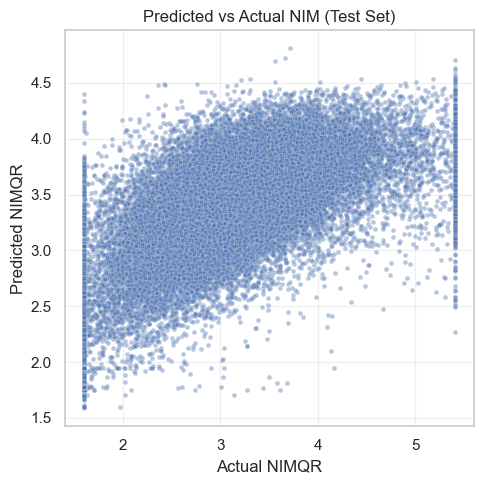

In [16]:
# === 2) Data ===
# df must already be loaded with columns: QUARTER, NIMQR, FEDFUNDS, equity_ratio, loan_ratio, deposit_ratio, funding_ratio, deposit_funding_ratio
feat = ["FEDFUNDS", "equity_ratio", "loan_ratio", "deposit_ratio", "funding_ratio", "deposit_funding_ratio"]
df["FEDFUNDS_SQ"] = df["FEDFUNDS"] ** 2
X = df[feat + ["FEDFUNDS_SQ"]].copy()
y = df["NIMQR"].copy()

mask = X.notnull().all(1) & y.notnull() & df["QUARTER"].notnull()
X, y, q = X[mask], y[mask], pd.PeriodIndex(df.loc[mask, "QUARTER"], freq="Q")

order = np.argsort(q.astype(str).values)
X, y, q = X.iloc[order], y.iloc[order], q[order]

cut = q.max() - 8  # last 8 quarters = test
train_idx = q <= cut
test_idx  = q >  cut

X_tr, y_tr = X[train_idx], y[train_idx]
X_te, y_te = X[test_idx],  y[test_idx]

print("Train/Test sizes:", X_tr.shape, X_te.shape)

# === 3) Model: HistGradientBoostingRegressor ===
model = HistGradientBoostingRegressor(
    max_iter=600,
    learning_rate=0.03,
    max_depth=4,
    random_state=42
)
model.fit(X_tr, y_tr)

# === 4) Eval ===
pred = model.predict(X_te)
mse = mean_squared_error(y_te, pred)
rmse = np.sqrt(mse)
print(f"Test RMSE: {rmse:.4f}")

plt.figure(figsize=(5,5))
sns.scatterplot(x=y_te, y=pred, alpha=0.4, s=12)
plt.xlabel("Actual NIMQR")
plt.ylabel("Predicted NIMQR")
plt.title("Predicted vs Actual NIM (Test Set)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

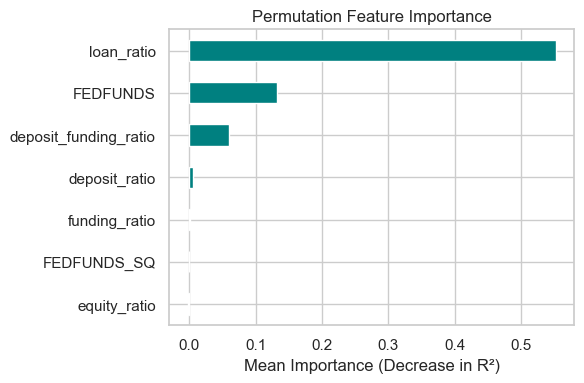

In [17]:
# === 5) Permutation Feature Importance ===
perm = permutation_importance(model, X_te, y_te, n_repeats=10, random_state=42, n_jobs=-1)
imp = pd.Series(perm.importances_mean, index=X_te.columns).sort_values(ascending=True)

plt.figure(figsize=(6,4))
imp.plot(kind="barh", color="teal")
plt.title("Permutation Feature Importance")
plt.xlabel("Mean Importance (Decrease in R²)")
plt.tight_layout()
plt.show()

ExactExplainer explainer: 4001it [06:25, 10.22it/s]                          


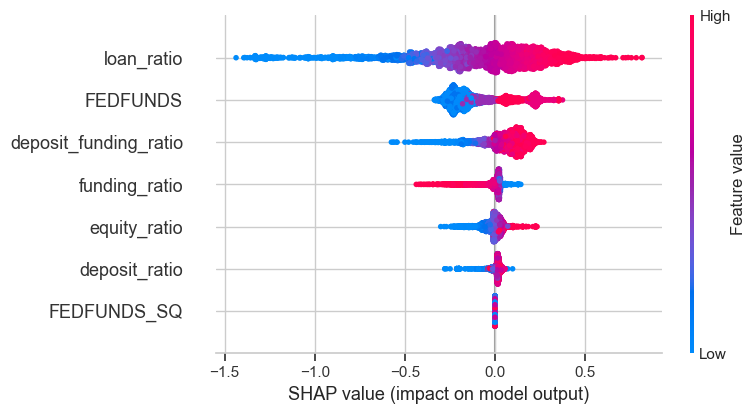

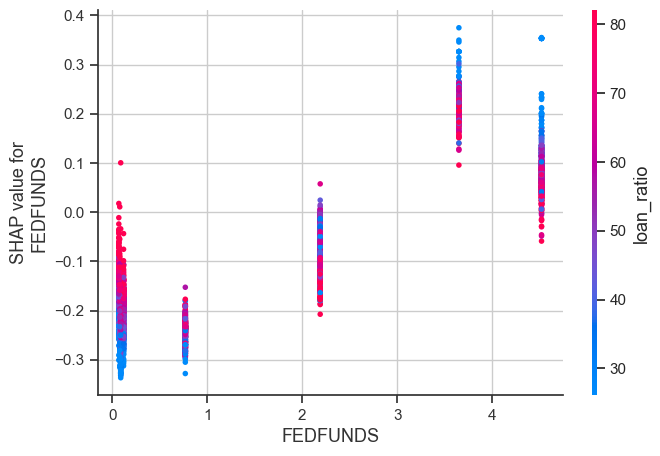

In [18]:
# === 6) SHAP Explainability ===
SAMPLE = min(4000, len(X_te))
Xs = X_te.sample(SAMPLE, random_state=42)

# model-agnostic explainer for sklearn HGBR
background = X_tr.sample(min(2000, len(X_tr)), random_state=42)
explainer = shap.Explainer(model.predict, background)
shap_values = explainer(Xs)

# SHAP summary (global)
shap.summary_plot(shap_values.values, Xs, feature_names=Xs.columns, show=True)

# SHAP dependence for the policy rate
shap.dependence_plot("FEDFUNDS", shap_values.values, Xs, feature_names=Xs.columns, show=True)